# Score distributions and metric comparison

Draws the G-Eval score distributions of faithful and modified summaries (the
paper's score-distribution figures, and the appendix figures for the other two
judges) and computes the metric comparison on the hand-written edits (Table 1).


In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")


def locate_root():
    override = os.environ.get("DECEPTION_PROJECT_ROOT")
    if override:
        return Path(override).resolve()
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "experiment.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not find experiment.yaml; set DECEPTION_PROJECT_ROOT.")


PROJECT_ROOT = locate_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from score_analysis import (
    CONDITION_LABELS,
    FAMILY_COLORS,
    FAMILY_LABELS,
    METRIC_LABELS,
    SUMMARY_CONDITION_LABELS,
    load_score_analysis,
    metric_order,
)

# The generated panel and the hand-annotated sample are both loaded, so manual
# edits appear as their own distributions beside the generated ones.
SCORE_SETS = ("main", "manual")
PLOT_DIR = PROJECT_ROOT / "results/figures/score_distributions"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df = load_score_analysis(project_root=PROJECT_ROOT, score_sets=SCORE_SETS)

In [2]:
import itertools

FAMILY_ORDER = [
    "factual_error",
    "aspect_deletion",
    "quantifier_swap",
    "review_filtering",
    "faithful",
]
# Groups are ordered as in the label tables of score_analysis.
CONDITION_ORDER = list(CONDITION_LABELS)
SUMMARY_ORDER = list(SUMMARY_CONDITION_LABELS)
DIRECTION_ORDER = ["advantageous", "disadvantageous", "not_applicable"]
GENERATOR_ORDER = [
    "primary_llm",
    "manual_annotation",
    "judge_model",
    "none",
]

def _order_map(values):
    return {value: index for index, value in enumerate(values)}


def build_plot_df(frame, metric_name):
    metric_df = frame.loc[frame["metric"] == metric_name].copy()
    if metric_df.empty:
        return metric_df, []

    metadata = metric_df[
        [
            "family",
            "condition",
            "summary_condition",
            "direction",
            "generator",
            "display_group",
            "display_key",
        ]
    ].drop_duplicates()
    metadata["_family"] = metadata["family"].map(_order_map(FAMILY_ORDER)).fillna(999)
    metadata["_condition"] = metadata["condition"].map(_order_map(CONDITION_ORDER)).fillna(999)
    metadata["_summary"] = metadata["summary_condition"].map(_order_map(SUMMARY_ORDER)).fillna(999)
    metadata["_direction"] = metadata["direction"].map(_order_map(DIRECTION_ORDER)).fillna(999)
    metadata["_generator"] = metadata["generator"].map(_order_map(GENERATOR_ORDER)).fillna(999)
    metadata = metadata.sort_values(
        ["_family", "_condition", "_summary", "_direction", "_generator"]
    ).drop_duplicates("display_key")
    group_order = metadata["display_key"].tolist()
    metric_df["plot_group"] = metric_df["display_key"]
    return metric_df, group_order


def _category_blocks(categories):
    """(family, first index, last index) for each run of consecutive groups of one family."""
    blocks = []
    for family, run in itertools.groupby(enumerate(categories), key=lambda item: item[1]):
        indices = [index for index, _ in run]
        blocks.append((family, indices[0], indices[-1]))
    return blocks


def _style_matplotlib():
    plt.rcdefaults()
    sns.set_style("whitegrid")
    plt.rcParams.update(
        {
            "font.size": 8,
            "axes.titlesize": 10,
            "axes.titleweight": "bold",
            "axes.labelsize": 7,
            "axes.labelweight": "bold",
            "xtick.labelsize": 9,
            "ytick.labelsize": 9,
            "legend.fontsize": 9,
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )


def _axis_geometry(scores, metric_name):
    if metric_name.startswith("geval_"):
        return {
            "bottom": 0.7,
            "top": 5.6,
            "header": 5.68,
            "rule": 5.58,
            "major": mticker.MultipleLocator(1),
            "minor": mticker.MultipleLocator(0.5),
        }

    finite = np.asarray(scores, dtype=float)
    finite = finite[np.isfinite(finite)]
    lower = float(finite.min())
    upper = float(finite.max())
    span = upper - lower
    if span == 0:
        span = max(abs(upper) * 0.2, 1.0)
    bottom = lower - 0.08 * span
    top = upper + 0.12 * span
    return {
        "bottom": bottom,
        "top": top,
        "header": top + 0.016 * span,
        "rule": top - 0.008 * span,
        "major": mticker.MaxNLocator(5),
        "minor": mticker.AutoMinorLocator(2),
    }


def _draw_category_headers(ax, blocks, geometry):
    for family, start, end in blocks:
        midpoint = (start + end) / 2
        color = FAMILY_COLORS[family]
        ax.text(
            midpoint,
            geometry["header"],
            FAMILY_LABELS[family],
            ha="center",
            va="bottom",
            fontsize=7,
            fontweight="bold",
            color=color,
        )
        ax.plot(
            [start - 0.3, end + 0.3],
            [geometry["rule"], geometry["rule"]],
            color=color,
            lw=1.5,
            solid_capstyle="round",
            clip_on=False,
        )


def _build_legend(ax, families_present):
    handles = [
        Patch(
            facecolor=FAMILY_COLORS[family],
            edgecolor="black",
            linewidth=0.4,
            label=FAMILY_LABELS[family],
        )
        for family in FAMILY_ORDER
        if family in families_present
    ]
    handles.append(
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=0.5,
            markersize=3,
            label="Mean",
        )
    )
    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        ncol=1,
        frameon=True,
        framealpha=0.9,
        edgecolor="#ccc",
        handlelength=1.0,
        handletextpad=0.4,
        labelspacing=0.4,
        borderpad=0.4,
    )


def plot_metric(metric_name, *, frame=None, plot_dir=None, save=True,
                drop_manual=False, title_suffix="", file_suffix=""):
    # `frame`/`plot_dir` let this same figure grammar draw from a different
    # scored dataset (e.g. a side scoring run) without duplicating the function.
    data = df if frame is None else frame
    target_dir = PLOT_DIR if plot_dir is None else plot_dir

    df_plot, group_order = build_plot_df(data, metric_name)
    if df_plot.empty:
        print(f"No data for metric: {metric_name}")
        return None

    # The hand-edited sample has its own figures further down. In this one it
    # contributed a single narrow group per family, a few hundred edits beside
    # thousands of generated ones, inviting a comparison the sample sizes do
    # not support. Off by default so the other callers are unaffected.
    if drop_manual:
        manual = {group for group in group_order if "(Manual)" in str(group)}
        if manual:
            df_plot = df_plot[~df_plot["plot_group"].isin(manual)]
            group_order = [group for group in group_order if group not in manual]
            if df_plot.empty:
                print(f"No non-manual data for metric: {metric_name}")
                return None

    group_metadata = (
        df_plot[["plot_group", "family", "display_group"]]
        .drop_duplicates("plot_group")
        .set_index("plot_group")
    )
    categories = [group_metadata.loc[group, "family"] for group in group_order]
    display_labels = [
        group_metadata.loc[group, "display_group"]
        for group in group_order
    ]
    palette = [FAMILY_COLORS[family] for family in categories]
    blocks = _category_blocks(categories)
    geometry = _axis_geometry(df_plot["raw_score"], metric_name)

    _style_matplotlib()
    fig, ax = plt.subplots(figsize=(10.2, 3.6), dpi=600)

    sns.boxplot(
        data=df_plot,
        x="plot_group",
        y="raw_score",
        order=group_order,
        palette=palette,
        width=0.48,
        whis=(2.5, 97.5),
        linewidth=0.5,
        fliersize=0.8,
        showmeans=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "markersize": 3.2,
            "markeredgewidth": 0.6,
        },
        medianprops={"color": "black", "linewidth": 0.7},
        whiskerprops={"color": "#333", "linewidth": 0.5},
        capprops={"color": "#333", "linewidth": 0.5},
        boxprops={"edgecolor": "black", "linewidth": 0.5},
        flierprops={
            "marker": ".",
            "markerfacecolor": "#666",
            "markeredgecolor": "none",
            "alpha": 0.5,
            "markersize": 3.0,
            "markeredgewidth": 0.5,
        },
        ax=ax,
    )

    for _, start, _ in blocks:
        if start > 0:
            ax.axvline(start - 0.5, color="#888", lw=0.6, ls="--", alpha=0.5)

    _draw_category_headers(ax, blocks, geometry)

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(
        display_labels,
        rotation=40,
        ha="right",
        rotation_mode="anchor",
        fontsize=8,
        linespacing=0.9,
    )
    ax.tick_params(axis="x", pad=6)

    metric_title = METRIC_LABELS.get(metric_name, metric_name.replace("_", " ").title())
    if metric_name == "geval_consistency":
        metric_title = "Consistency"
    elif metric_name == "geval_relevance":
        metric_title = "Relevance"
    ax.set_xlabel("")
    ax.set_ylabel(f"{metric_title} Score", fontsize=9)
    ax.set_title(f"{metric_title} Score Distributions{title_suffix}", pad=15)
    ax.set_ylim(geometry["bottom"], geometry["top"])
    ax.yaxis.set_major_locator(geometry["major"])
    ax.yaxis.set_minor_locator(geometry["minor"])

    ax.set_facecolor("#fafafa")
    ax.grid(True, axis="y", color="#ccc", alpha=0.5, linewidth=0.4)
    ax.grid(True, axis="x", color="#e0e0e0", alpha=0.3, linewidth=0.3)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_linewidth(0.6)
        ax.spines[spine].set_color("#333")

    _build_legend(ax, set(categories))

    fig.tight_layout(pad=0.2)
    fig.subplots_adjust(top=0.86, bottom=0.43, right=0.86)

    if save:
        for extension in ("png", "pdf"):
            output = target_dir / f"score_distribution_{metric_name}{file_suffix}.{extension}"
            fig.savefig(output, dpi=600, bbox_inches="tight")
            print(f"Saved: {os.path.relpath(output, PROJECT_ROOT)}")
    return fig

## The same distributions, once per G-Eval judge

Every judge's G-Eval scores are drawn with the same groups, axis and colours.
The configured judge (`geval_judge` in `experiment.yaml`) gives the paper's
figures, saved as `score_distribution_<metric>_<judge>`; the other judges, for
the appendix, are saved under `results/figures/score_distributions/by_judge/<judge>/`
with the judge's model in the title.


Saved: results/figures/score_distributions/by_judge/gemma4/score_distribution_geval_consistency.png


Saved: results/figures/score_distributions/by_judge/gemma4/score_distribution_geval_consistency.pdf


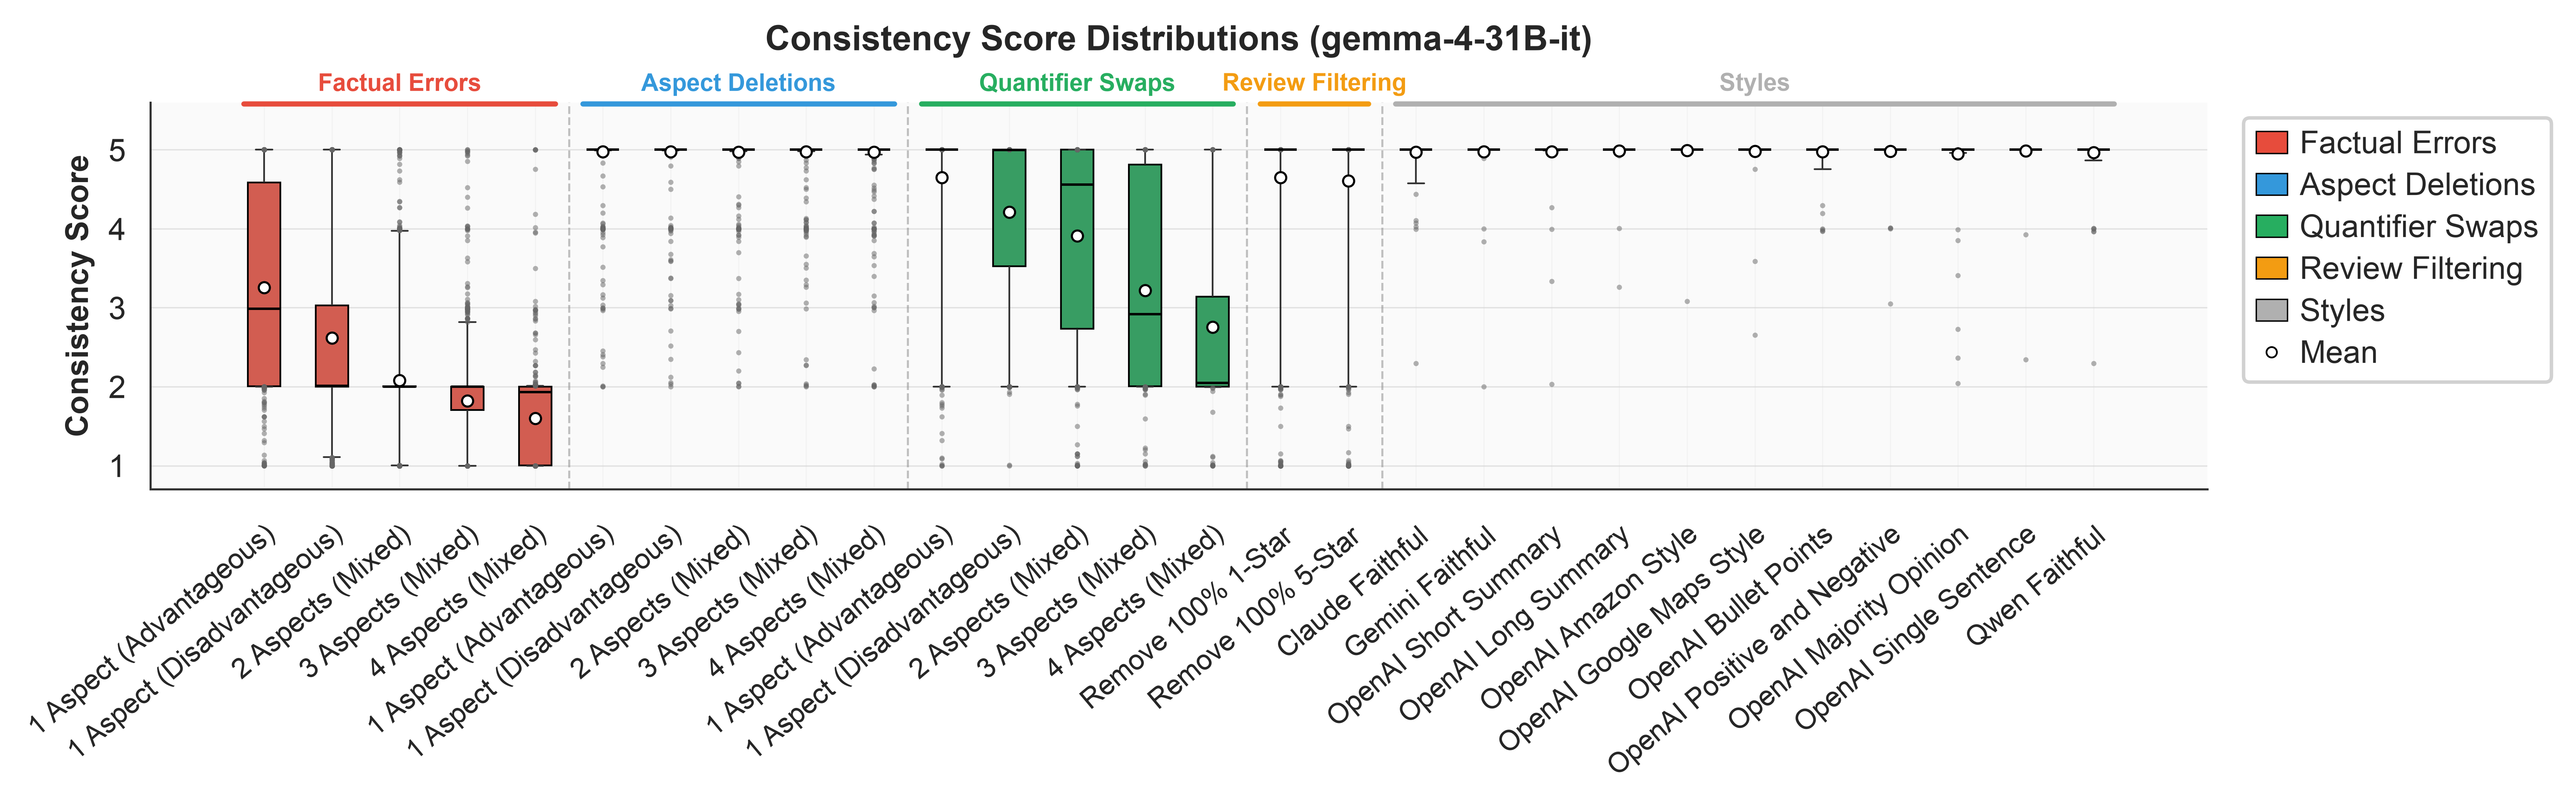

Saved: results/figures/score_distributions/by_judge/gemma4/score_distribution_geval_relevance.png


Saved: results/figures/score_distributions/by_judge/gemma4/score_distribution_geval_relevance.pdf


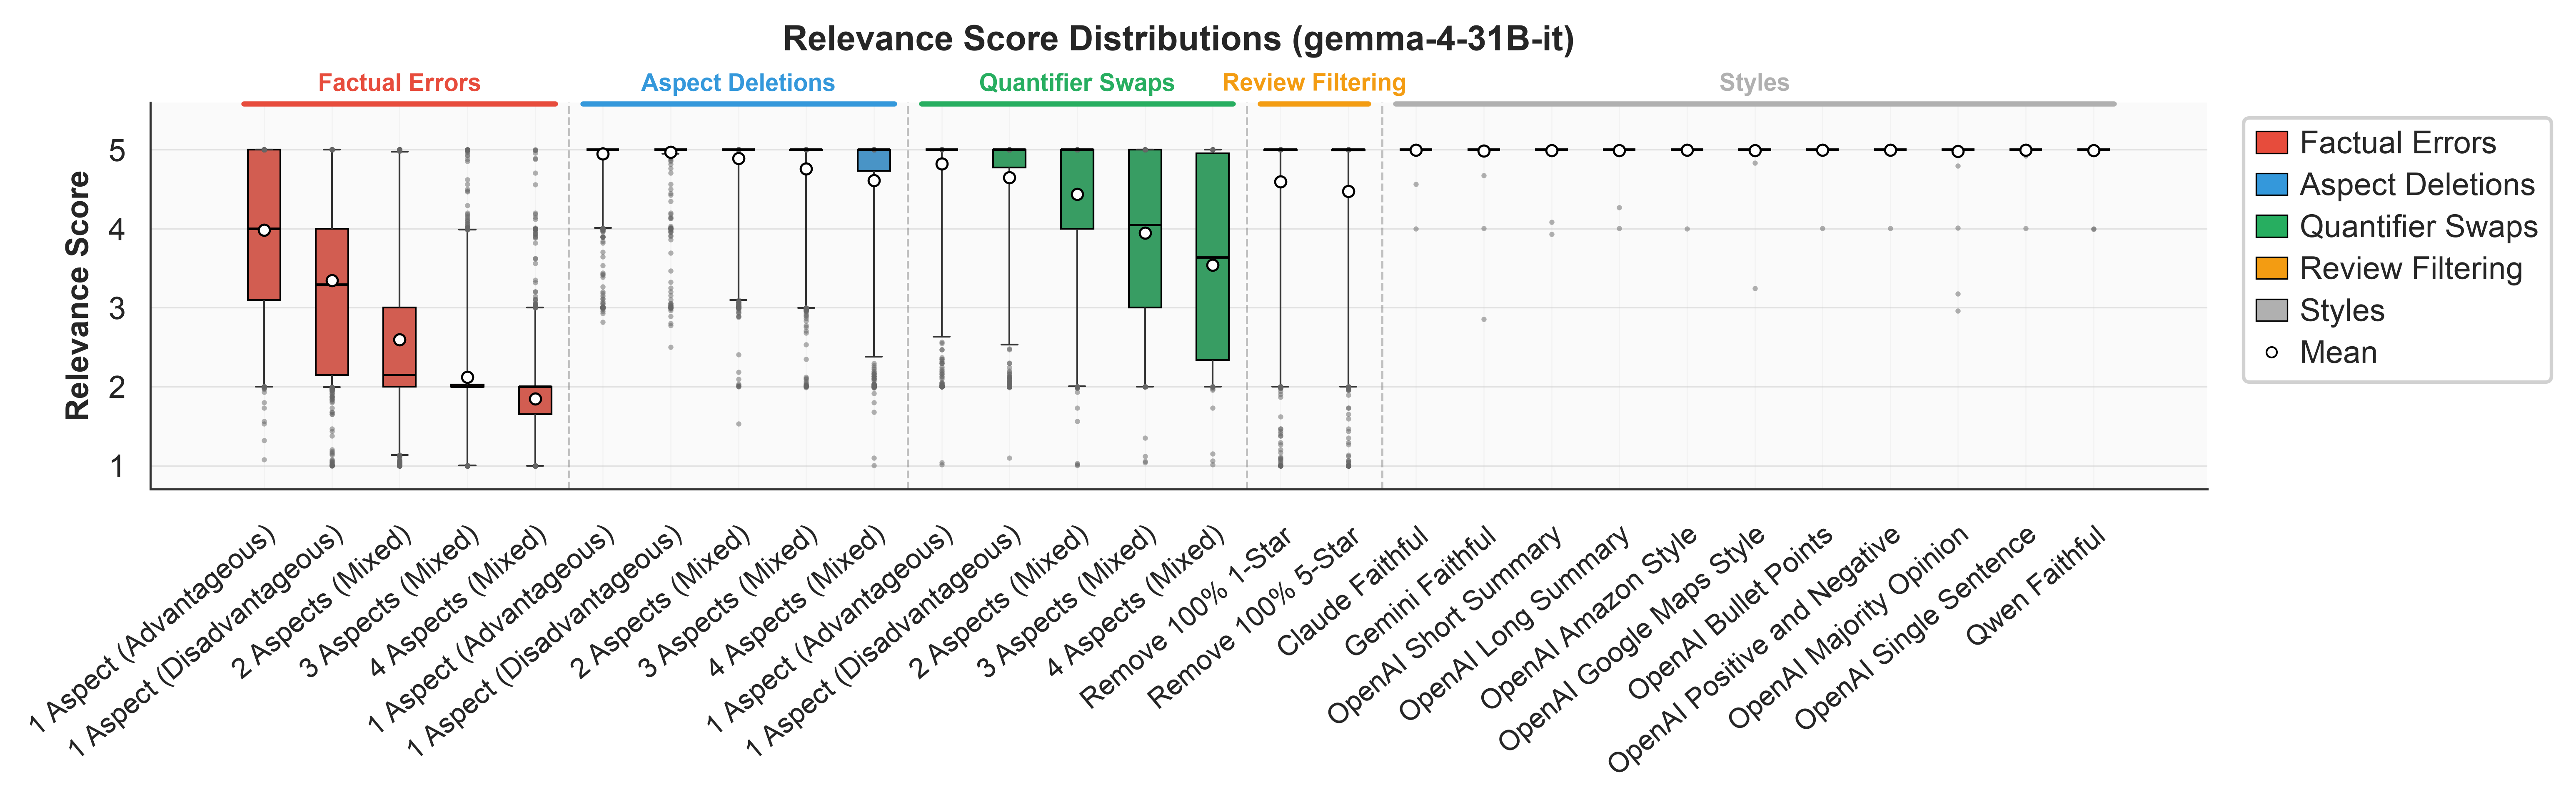

Saved: results/figures/score_distributions/by_judge/olmo31/score_distribution_geval_consistency.png


Saved: results/figures/score_distributions/by_judge/olmo31/score_distribution_geval_consistency.pdf


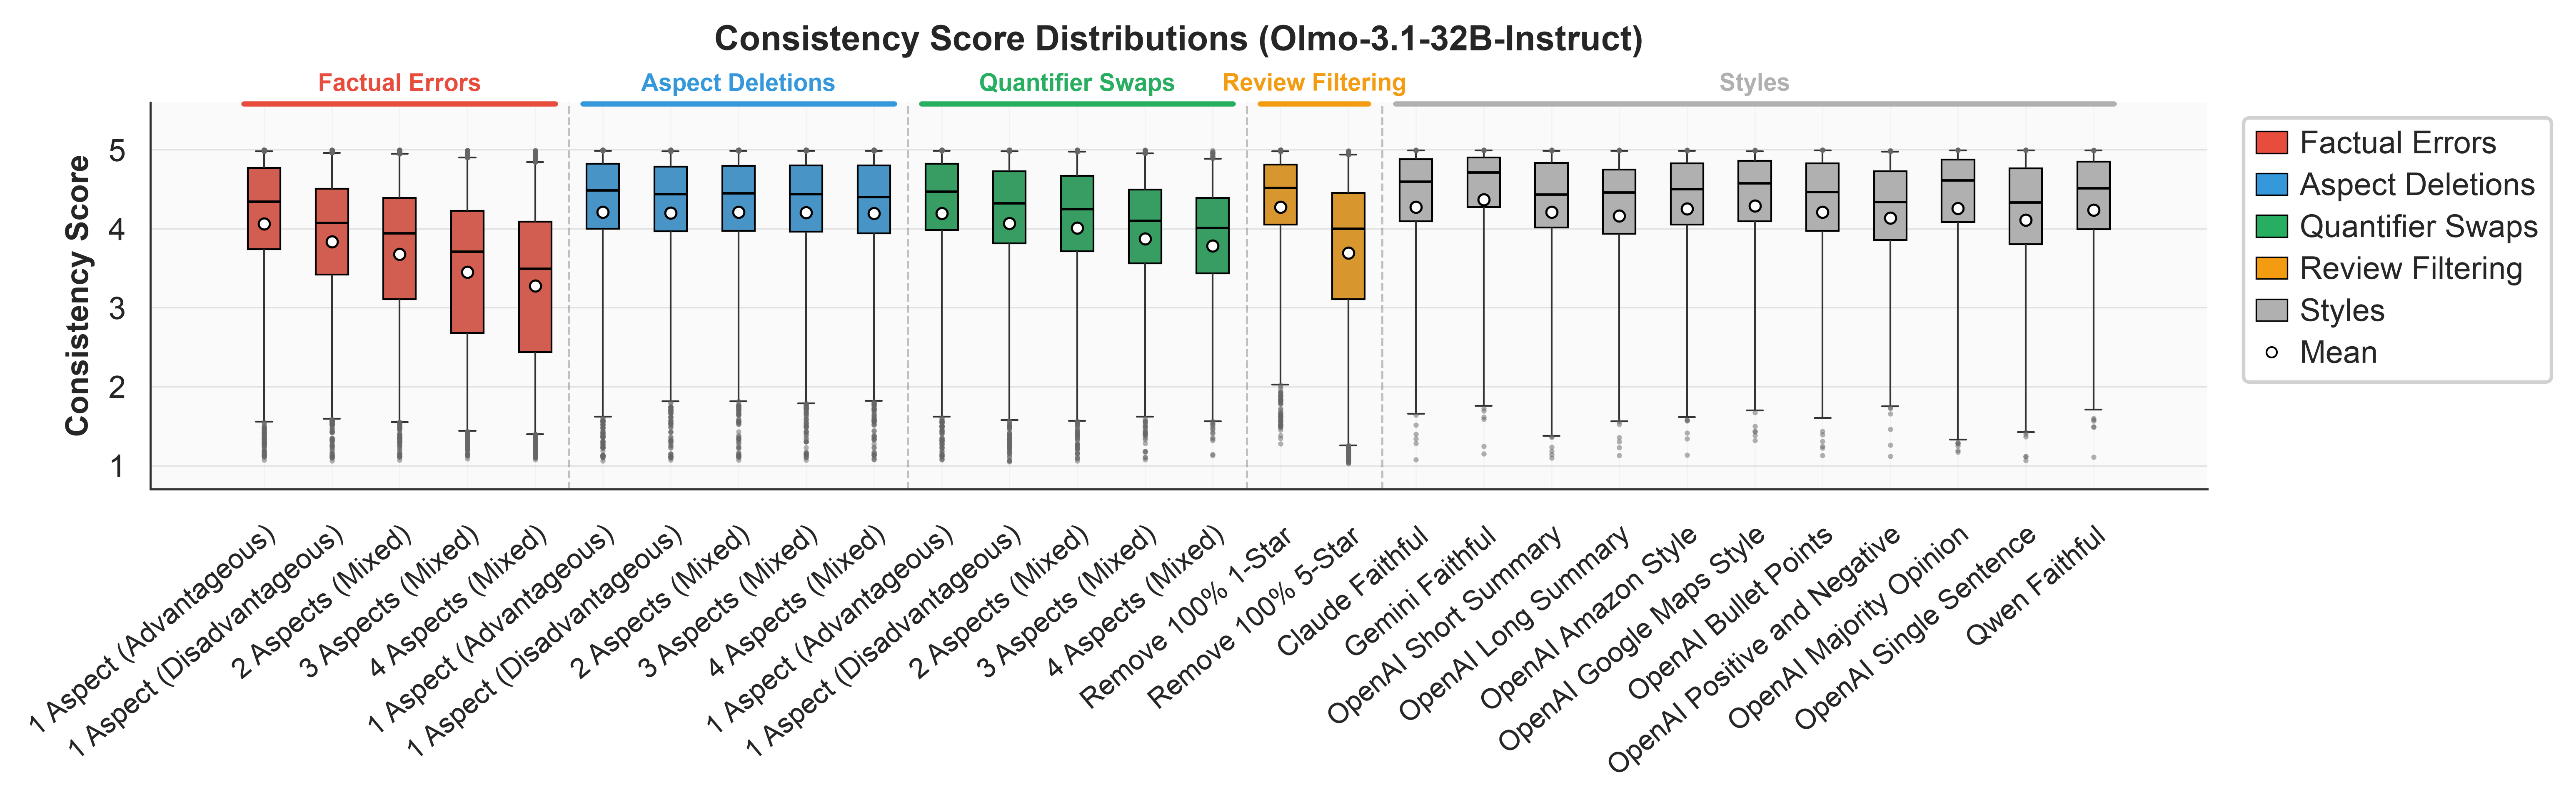

Saved: results/figures/score_distributions/by_judge/olmo31/score_distribution_geval_relevance.png


Saved: results/figures/score_distributions/by_judge/olmo31/score_distribution_geval_relevance.pdf


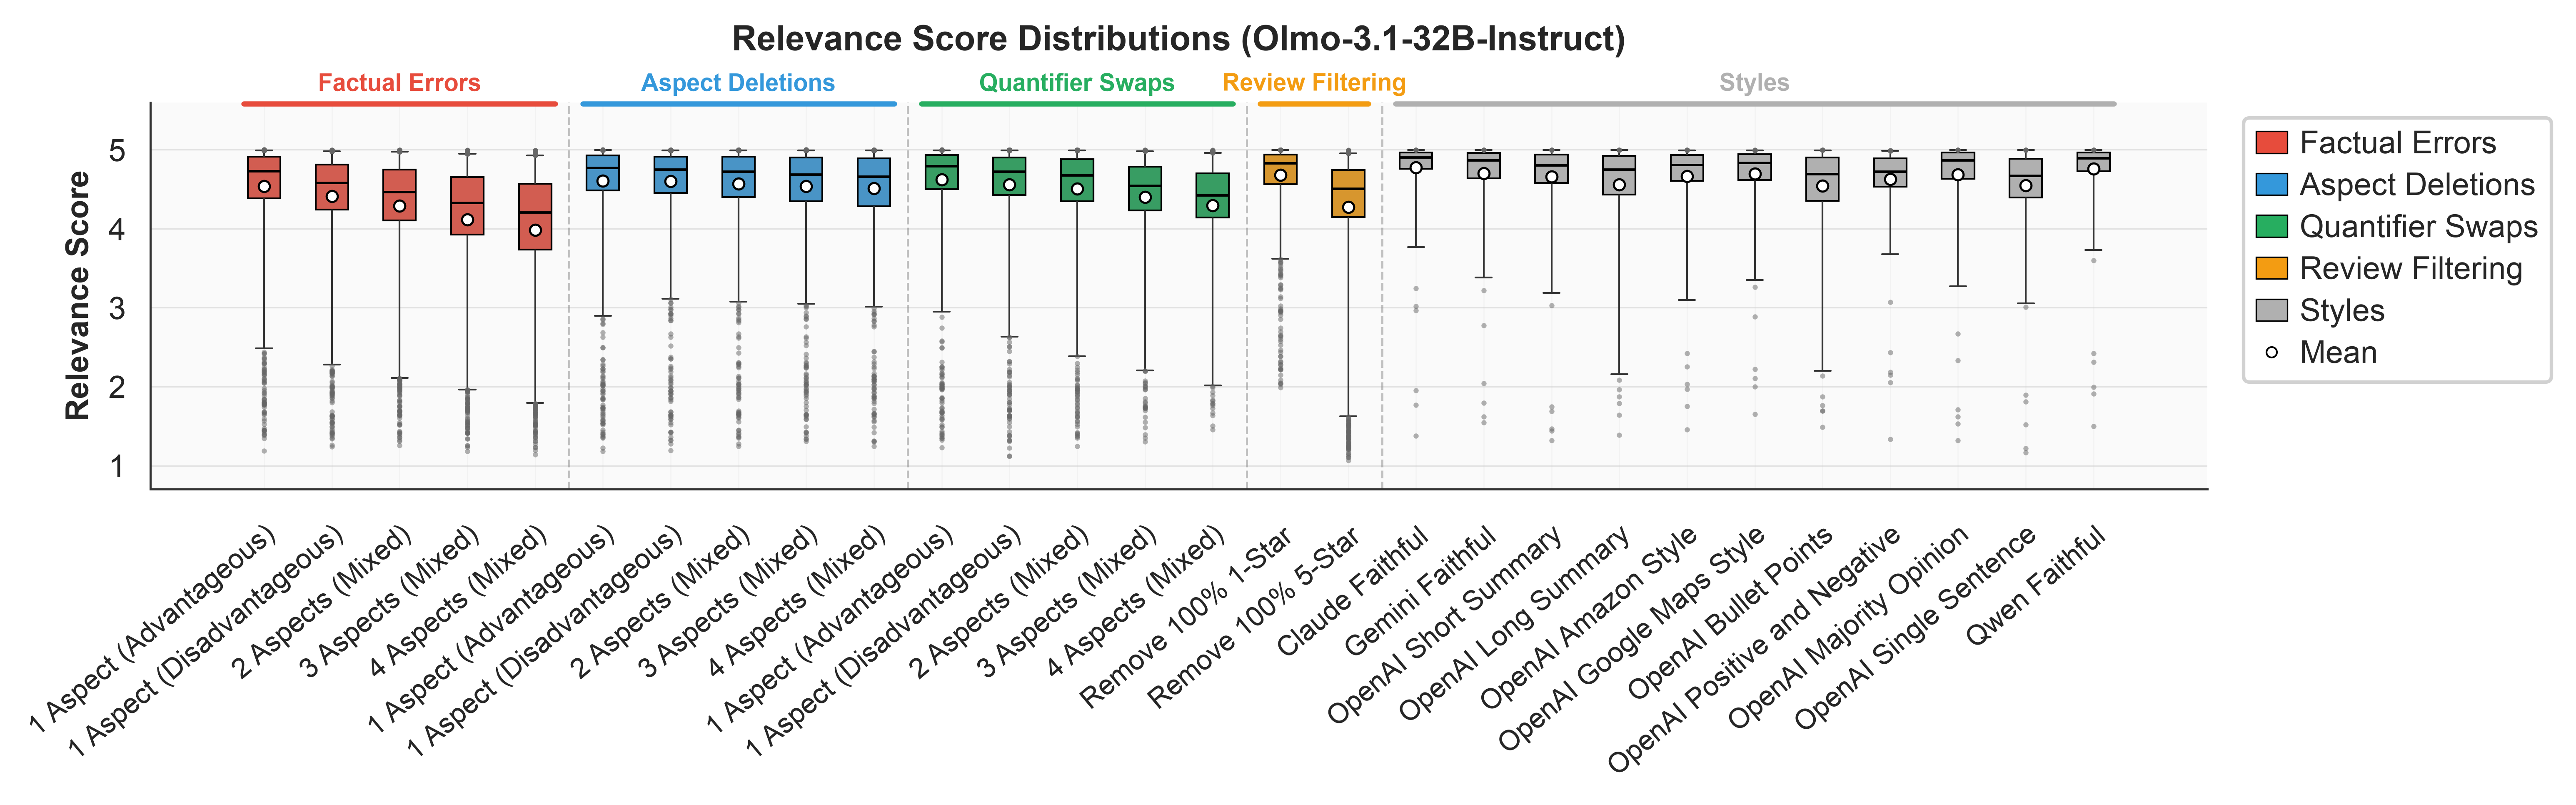

Saved: results/figures/score_distributions/score_distribution_geval_consistency_qwen36.png


Saved: results/figures/score_distributions/score_distribution_geval_consistency_qwen36.pdf


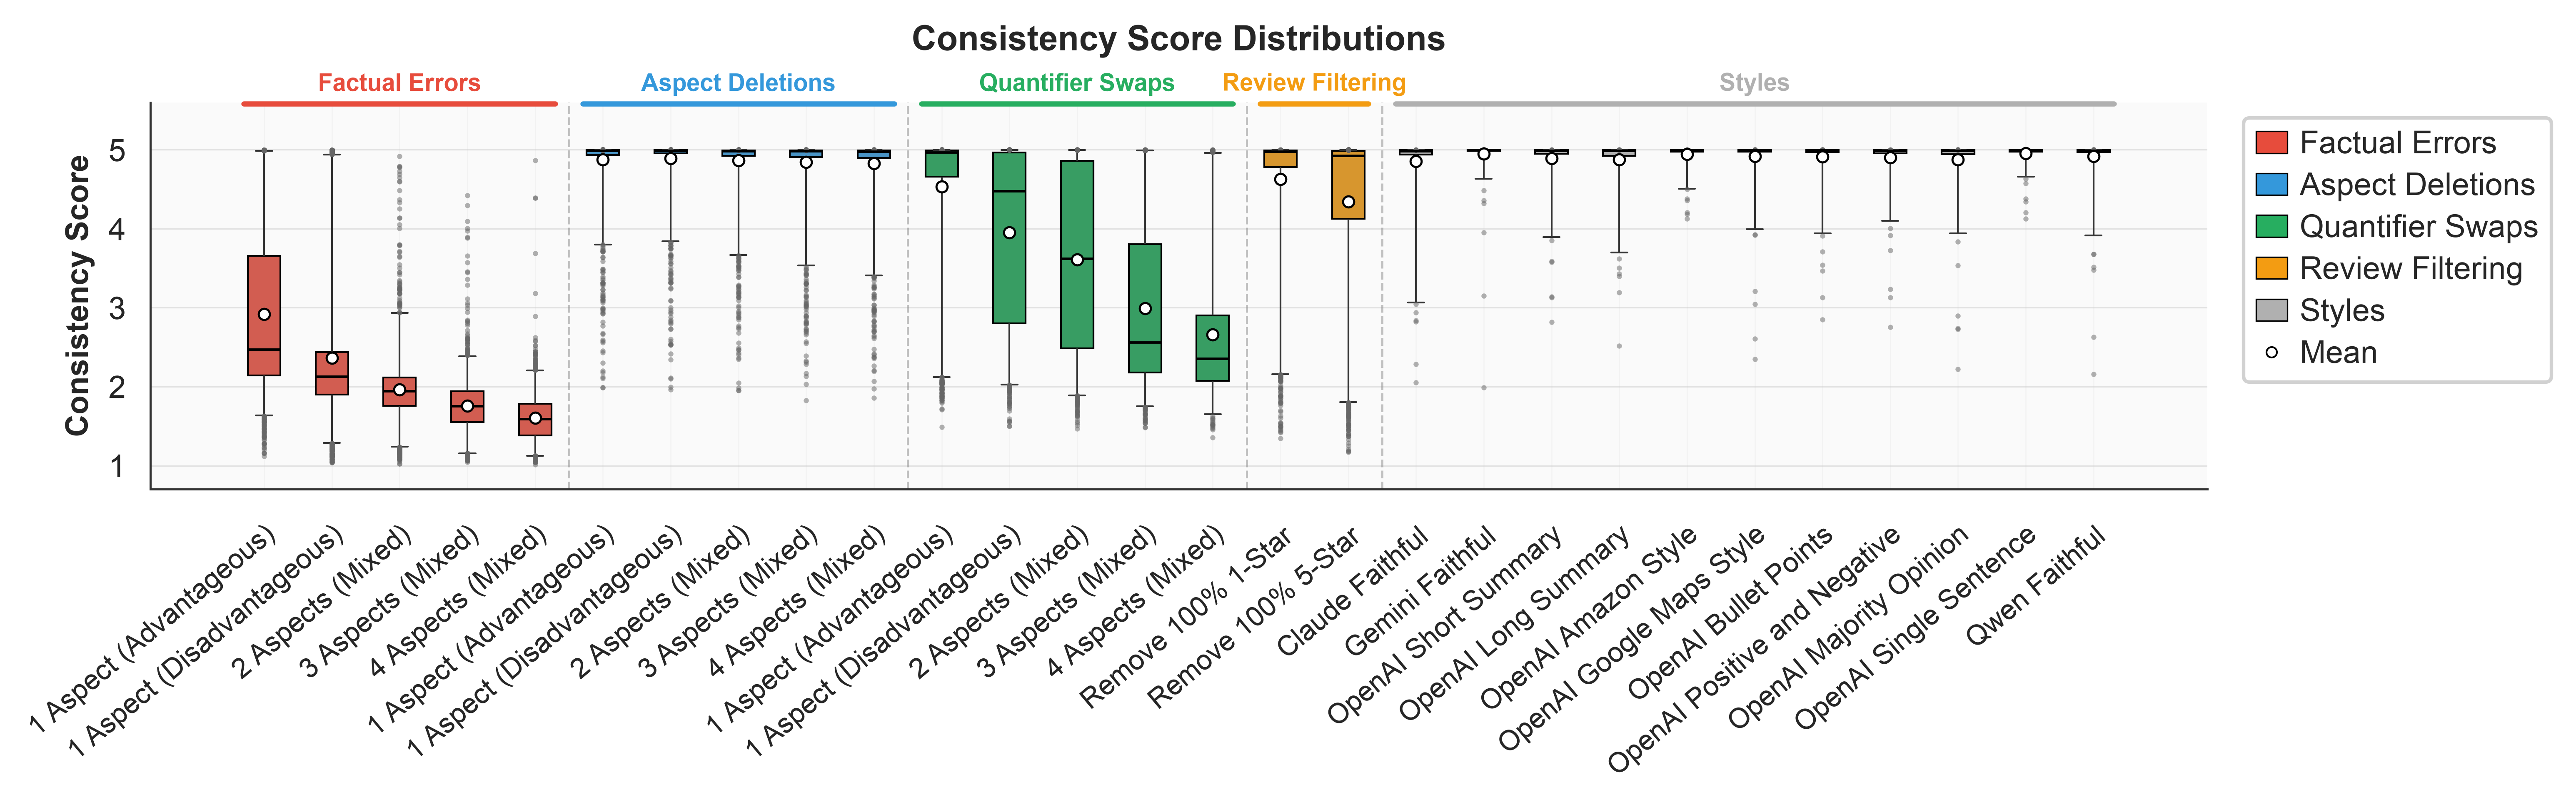

Saved: results/figures/score_distributions/score_distribution_geval_relevance_qwen36.png


Saved: results/figures/score_distributions/score_distribution_geval_relevance_qwen36.pdf


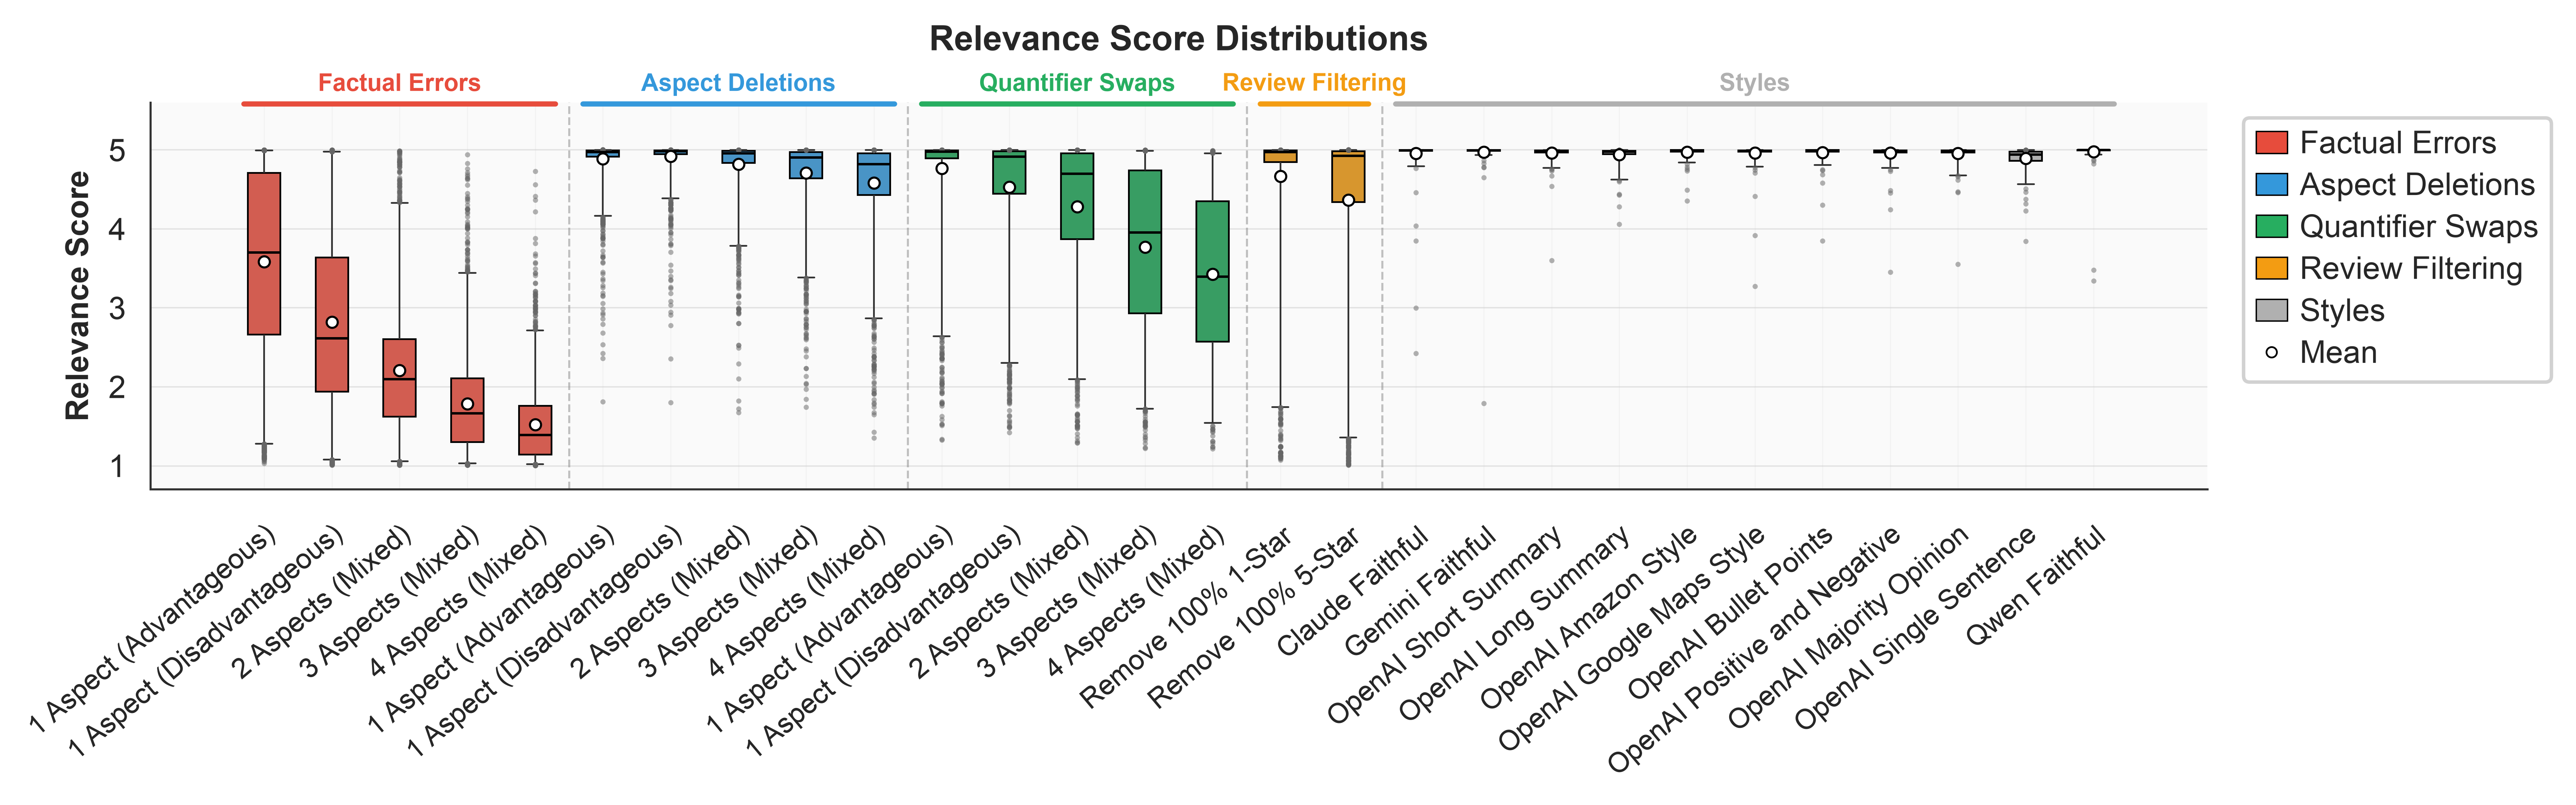

In [3]:
from score_analysis import active_geval_judge, load_config

# Each configured judge's model, for the figure titles.
_config = load_config(str(PROJECT_ROOT / "experiment.yaml"))
JUDGE_MODELS = {name: active_geval_judge(_config, name)[1]["model"]
                for name in _config.get("geval_judges", {})}

JUDGE_DISTRIBUTION_DIR = PLOT_DIR / "by_judge"

df_all_judges = load_score_analysis(
    project_root=PROJECT_ROOT,
    score_sets=SCORE_SETS,
    keep_all_judges=True,
)
df_all_judges = df_all_judges[df_all_judges["metric"].str.startswith("geval_")]

judge_figures = {}
for name in sorted(df_all_judges["judge"].dropna().unique()):
    frame = df_all_judges[df_all_judges["judge"] == name]
    model = JUDGE_MODELS[name]
    for metric_name in metric_order(frame):
        if name == _config["geval_judge"]:
            # The paper's figure: the model is named in the file, not the title.
            judge_figures[(name, metric_name)] = plot_metric(
                metric_name, frame=frame, plot_dir=PLOT_DIR,
                drop_manual=True, file_suffix=f"_{name}")
        else:
            plot_dir = JUDGE_DISTRIBUTION_DIR / name
            plot_dir.mkdir(parents=True, exist_ok=True)
            judge_figures[(name, metric_name)] = plot_metric(
                metric_name, frame=frame, plot_dir=plot_dir,
                drop_manual=True, title_suffix=f" ({model.split('/')[-1]})")
        plt.show()

## Metric comparison on the hand-written edits

How well each reference-free metric separates the 100 unmodified parent
summaries from their hand-written and LLM-generated one-aspect modifications,
measured by AUROC: the paper's metric-comparison table, written to
`results/tables/metric_comparison.tex`.


In [4]:
TABLE_DIR = PROJECT_ROOT / "results/tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def manual_comparison_frame(frame):
    """The hand edits plus the faithful parents they were made from.

    Both halves are needed: the parents are the reference every panel is read
    against, and a metric that scored only one of them cannot be plotted.
    """

    edits = frame.loc[frame["generator"] == "manual_annotation"]

    if edits.empty:
        return edits, []

    parents = set(edits["parent_summary_id"])
    baseline = frame.loc[
        (frame["family"] == "faithful") & (frame["record_id"].isin(parents))
    ]
    combined = pd.concat([baseline, edits], ignore_index=True)

    # Only the metrics that scored both the parents and the edits.
    usable = [metric_name for metric_name in metric_order(combined)
              if combined.loc[combined["metric"] == metric_name, "family"].nunique() > 1]
    combined = combined.loc[combined["metric"].isin(usable)].copy()

    return combined, usable


# ─── Sensitivity table: AUROC per metric and modification type ───
#
# Human edits (Manual) beside the LLM edits of the same parents (LLM): the main
# study's one-aspect conditions, made by the primary modifier with the main
# prompts, both directions pooled. Each column uses only the products that have
# both a hand edit and a valid LLM edit, against the same unmodified parents.
# Scores are put in the faithful orientation first (the negated anomaly score),
# so an AUROC above 0.5 means the modified summaries scored lower.
from scipy import stats

SENSITIVITY_TABLE_PATH = TABLE_DIR / "metric_comparison.tex"
# Every metric but G-Eval scored the LLM edits in their own run (the
# "llm_matched" score set); G-Eval's come from the main panel.
SENSITIVITY_COLUMNS = [
    ("factual_error", "Factual Error"),
    ("aspect_deletion", "Aspect Deletion"),
    ("quantifier_swap", "Quantifier Swap"),
]
EDIT_SOURCES = ("Manual", "LLM")
# (family, label) per metric, in the order the table lists them: the paper's
# seven methodological families, in the order its text introduces them.
SENSITIVITY_METRICS = {
    "geval_consistency": ("LLM-as-a-judge", "G-Eval Consistency"),
    "geval_relevance": ("LLM-as-a-judge", "G-Eval Relevance"),
    # SummaC with one review per premise, since its published cap of 100
    # premises discards most of each review set.
    "summac_zs": ("NLI-based", "SummaC-ZS"),
    "summac_conv": ("NLI-based", "SummaC-Conv"),
    "qafacteval": ("QA-based", "QAFactEval"),
    "supert": ("Pseudo-reference-based", "SUPERT"),
    # AlignScore and MiniCheck-7B as published.
    "alignscore": ("Alignment-based", "AlignScore"),
    "factgraph": ("Graph-based", "FactGraph"),
    "minicheck_7b": ("Document-grounded fact-checking", "MiniCheck-7B"),
}
# The family as the table's Family column prints it, short enough to share a
# row with the metric's name.
FAMILY_ABBREVIATIONS = {
    "LLM-as-a-judge": "LLM judge",
    "NLI-based": "NLI",
    "QA-based": "QA",
    "Pseudo-reference-based": "Pseudo-ref.",
    "Alignment-based": "Alignment",
    "Graph-based": "Graph",
    "Document-grounded fact-checking": "Fact-checking",
}


def auroc(faithful, modified):
    """P(a faithful summary scores higher than a modified one), ties counting half:
    the Mann-Whitney U statistic over all faithful x modified pairs."""
    return stats.mannwhitneyu(faithful, modified).statistic / (len(faithful) * len(modified))


def llm_matched_edits(parents):
    """The LLM's one-aspect edits of these parents, with every score available."""

    frames = [df, load_score_analysis(project_root=PROJECT_ROOT, score_sets=("llm_matched",))]
    rows = pd.concat(frames, ignore_index=True)
    rows = rows.loc[
        rows["generator"].eq("primary_llm")
        & rows["parent_summary_id"].isin(parents)
        & rows["condition"].astype(str).str.contains("_count1_", regex=False)
    ]
    return rows.drop_duplicates(["record_id", "metric"], keep="last")


def metric_sensitivity(frame=None):
    """AUROC per (metric, modification type, edit source)."""

    combined, metrics = manual_comparison_frame(df if frame is None else frame)
    if combined.empty:
        return None

    parents = set(combined.loc[combined["family"] == "faithful", "record_id"])
    llm = llm_matched_edits(parents)
    edits = {
        "Manual": combined.loc[combined["family"] != "faithful"],
        "LLM": llm,
    }
    edits = {source: rows.assign(score=-rows["anomaly_score"]) for source, rows in edits.items()}
    faithful_all = combined.loc[combined["family"] == "faithful"]
    faithful_all = faithful_all.assign(score=-faithful_all["anomaly_score"])

    # The products a column is computed on: those with both a hand edit and an LLM edit.
    products = {
        family: sorted(
            set(edits["Manual"].loc[edits["Manual"]["family"] == family, "product_id"])
            & set(llm.loc[llm["family"] == family, "product_id"])
        )
        for family, _ in SENSITIVITY_COLUMNS
    }

    records = []
    for metric_name in [m for m in SENSITIVITY_METRICS if m in metrics]:
        faithful = faithful_all.loc[faithful_all["metric"] == metric_name].dropna(subset=["score"])

        for family, _ in SENSITIVITY_COLUMNS:
            groups = {
                source: rows.loc[(rows["metric"] == metric_name) & (rows["family"] == family)]
                .dropna(subset=["score"])
                for source, rows in edits.items()
            }
            sources = [source for source in EDIT_SOURCES
                       if set(products[family]) <= set(groups[source]["product_id"])]
            if not sources or len(faithful) < 2:
                continue

            in_column = faithful["product_id"].isin(products[family])
            faithful_scores = faithful.loc[in_column, "score"].to_numpy()
            for source in sources:
                rows = groups[source]
                modified = rows.loc[rows["product_id"].isin(products[family]), "score"].to_numpy()
                records.append({
                    "metric": metric_name,
                    "family": family,
                    "edits": source,
                    "products": len(products[family]),
                    "modified": len(modified),
                    "auroc": auroc(faithful_scores, modified),
                })

    return pd.DataFrame(records).set_index(["metric", "family", "edits"])


def render_sensitivity_table(stats, rows, caption, label, path):
    """One table in the layout of Table tab:metric_comparison, for the given rows."""

    present = set(stats.index.get_level_values("metric"))
    rows = {metric: spec for metric, spec in rows.items() if metric in present}

    # The most sensitive metric per column within each edit source: the
    # largest AUROC among this table's rows.
    best = {}
    for (metric_name, family, source), row in stats.iterrows():
        if metric_name in rows:
            best[(source, family)] = max(best.get((source, family), row["auroc"]), row["auroc"])

    def cell(metric_name, family, source):
        if (metric_name, family, source) not in stats.index:
            # Not yet scored on every product of the column.
            return "XX"
        value = stats.loc[(metric_name, family, source), "auroc"]
        text = f"{value:.2f}"
        return rf"\textbf{{{text}}}" if np.isclose(value, best[(source, family)]) else text

    # One row per metric, its family in a column beside its name rather than
    # on a header row of its own, which saves a row per family. Manual and LLM
    # sit side by side per column.
    width = 2 + 2 * len(SENSITIVITY_COLUMNS)
    body = []
    for metric_name, (family, name) in rows.items():
        values = [
            cell(metric_name, family_name, source)
            for family_name, _ in SENSITIVITY_COLUMNS
            for source in EDIT_SOURCES
        ]
        family_text = FAMILY_ABBREVIATIONS.get(family, family)
        body += [rf"{name} & {family_text}", "& " + " & ".join(values) + r" \\"]

    column_headers = "& \n" + "\n".join(
        rf"& \multicolumn{{{len(EDIT_SOURCES)}}}{{c}}{{\textbf{{{title}}}}}"
        for _, title in SENSITIVITY_COLUMNS
    )
    # The last rule is trimmed on the left only, flush with the table's edge.
    rules = [
        rf"\cmidrule({'l' if i == len(SENSITIVITY_COLUMNS) - 1 else 'lr'})"
        rf"{{{3 + 2 * i}-{4 + 2 * i}}}"
        for i in range(len(SENSITIVITY_COLUMNS))
    ]
    source_headers = "\n".join(
        "& " + " & ".join(rf"\textbf{{{source}}}" for source in EDIT_SOURCES)
        for _ in SENSITIVITY_COLUMNS
    )

    latex = "\n".join([
        r"\begin{table*}[t]",
        r"\centering",
        r"\small",
        r"\setlength{\tabcolsep}{6pt}",
        r"\renewcommand{\arraystretch}{1.12}",
        r"\caption{" + caption + "}",
        rf"\label{{{label}}}",
        r"\begin{tabular}{ll" + "c" * (width - 2) + "}",
        r"\toprule",
        column_headers + r" \\",
        *rules,
        r"\textbf{Metric} & \textbf{Family}",
        source_headers + r" \\",
        r"\midrule",
        "",
        *body,
        "",
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table*}",
    ])

    path.write_text(latex + "\n", encoding="utf-8")
    print(f"Saved: {os.path.relpath(path, PROJECT_ROOT)}")
    return latex


def metric_sensitivity_table(frame=None):
    stats = metric_sensitivity(frame)

    judge = JUDGE_MODELS[df.attrs["geval_judge"]].split("/")[-1]
    render_sensitivity_table(
        stats,
        SENSITIVITY_METRICS,
        r"Sensitivity of reference-free summarization quality metrics to manual and LLM-generated one-aspect "
        r"modifications of the same products, measured by AUROC ($0.5$ = chance). LLM "
        r"modifications pool advantageous and disadvantageous edits. "
        rf"G-Eval uses {judge}. Bold values indicate the highest AUROC for each "
        r"modification type and origin.",
        "tab:metric_comparison",
        SENSITIVITY_TABLE_PATH,
    )
    return stats


metric_sensitivity_stats = metric_sensitivity_table()

Saved: results/tables/metric_comparison.tex
